# Day 44 | Prepare a Local LLM App for Deployment

**KGP Talkie**

Map the app, model server, files, settings, and project checks.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

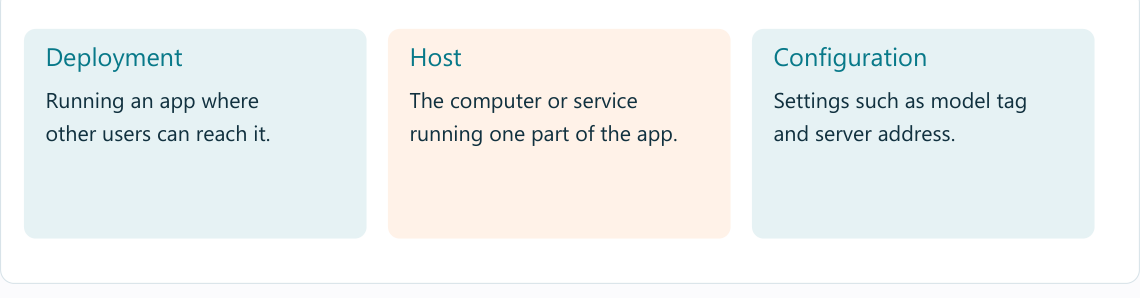

In [4]:
import requests
import importlib.metadata as packages

In [5]:
print("Python model tag:", os.getenv("KGP_MODEL", "llama3.2"))

Python model tag: llama3.2


A remote deployment needs its own reachable model server address. localhost always points to the app host itself.

In [6]:
server = os.getenv("OLLAMA_BASE_URL", "http://localhost:11434")

In [7]:
health = requests.get(server + "/api/tags", timeout=10)
health.raise_for_status()

In [8]:
[model["name"] for model in health.json()["models"]]

['nomic-embed-text:latest',
 'uncensored_1:latest',
 'uncensored:latest',
 'cooper:latest',
 'sheldon:latest',
 'llama3.2:latest',
 'qwen2.5:0.5b-small-my-model-copy',
 'qwen2.5:0.5b']

In [9]:
{name: packages.version(name) for name in ["langchain", "langchain-ollama", "streamlit", "pymupdf"]}

{'langchain': '1.4.4',
 'langchain-ollama': '1.1.0',
 'streamlit': '1.65.0',
 'pymupdf': '1.28.2'}

This file contains settings only, not real passwords. Copy it locally and keep real secrets out of Git.

In [10]:
print((BASE / ".env.example").read_text())

KGP_MODEL=llama3.2
OLLAMA_BASE_URL=http://localhost:11434
LANGSMITH_TRACING=false



## Final project checks

| Check | Expected behavior |
|---|---|
| Two different resumes | Two different reviewed records |
| Missing email | null, not an invented address |
| Blank PDF text | A clear OCR or empty-text message |
| Server stopped | A clear connection error, no fake result |
| App on a new host | Model URL points to that host's reachable server |

These checks describe the deployment work. No public server is created by this notebook.

In [11]:
payload = {"model": os.getenv("KGP_MODEL", "llama3.2"), "messages": [{"role": "user", "content": "Say ready in one word."}], "stream": False, "options": {"num_predict": 16}}

In [12]:
result = requests.post(server + "/api/chat", json=payload, timeout=180)
result.raise_for_status()

This fresh request checks a real local generation, not just a successful server connection.

In [13]:
print(result.json()["message"]["content"])

Ready.


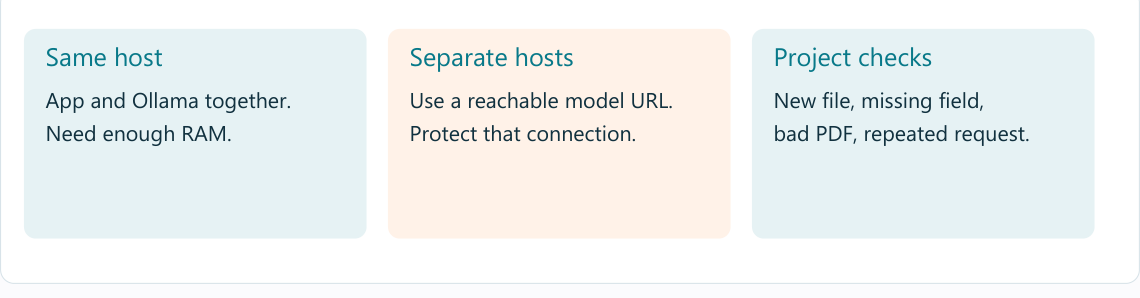

## Try a fresh input

Review the project with two fresh resumes and an empty input. Record what passed and what still needs a real deployment test.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-deploy-resume-parsing).